<a href="https://colab.research.google.com/github/ian-ren03/NLP-TC3009-A01384161/blob/main/notebooks/01_ModeloA_BiLSTM_atencion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os, json, random, torch, numpy as np
from google.colab import drive

drive.mount('/content/drive')
SAVE_DIR = '/content/drive/MyDrive/PROYECTO FINAL NLP - ntm-en-es'
os.makedirs(SAVE_DIR, exist_ok=True)

SEED = 23
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Dispositivo: ', device)
!pip install -q sacrebleu sentencepiece sacremoses

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dispositivo:  cuda


In [2]:
!git clone https://github.com/ian-ren03/NLP-TC3009-A01384161.git
%cd NLP-TC3009-A01384161
import sys; sys.path.append('.')

fatal: destination path 'NLP-TC3009-A01384161' already exists and is not an empty directory.
/content/NLP-TC3009-A01384161


In [3]:
!git pull

Already up to date.


## Listing 1

In [4]:
!wget -q https://www.manythings.org/anki/spa-eng.zip && unzip -q -o spa-eng.zip

import random, hashlib
with open('spa.txt', 'r', encoding='utf-8') as f:
    raw_pairs = [line.strip().split('\t')[:2] for line in f if '\t' in line]

filtered_pairs = [
    (en, es) for en, es in raw_pairs
    if 8 <= len(en.split()) <= 120 and len(es.split()) <= 120
]

rng = random.Random(23)
rng.shuffle(filtered_pairs)

n = len(filtered_pairs)
n_train = int(0.80 * n)
n_val = int(0.10 * n)
train_pairs = filtered_pairs[:n_train]
val_pairs = filtered_pairs[n_train:n_train + n_val]
test_pairs = filtered_pairs[n_train + n_val:]

test_hash = hashlib.sha256("\n".join([p[0] for p in test_pairs]).encode()).hexdigest()[:12]
print(f"Train: {len(train_pairs)} | Val: {len(val_pairs)} | Test: {len(test_pairs)}")
print(f"SHA-256 Test Audit ID: {test_hash}")

Train: 29130 | Val: 3641 | Test: 3642
SHA-256 Test Audit ID: dbac04ac5648


## Vocabularios

In [5]:
from torch.utils.data import DataLoader
from src.data import *

eng_word2idx = build_vocab([en for en, _ in train_pairs], min_freq = 2, max_size = 20000)
spa_word2idx = build_vocab([es for _, es in train_pairs], min_freq = 2, max_size = 20000)
print('Vocab Inglés: ', len(eng_word2idx), '| Vocab Español:', len(spa_word2idx))

## Ratio de <unk>
def unk_rate(pairs, idx, col):
  toks = [idx.get(w, UNK_IDX) for p in pairs for w in clean_text(p[col]).split()]
  return sum(t == UNK_IDX for t in toks) / len(toks)

for name, ps in [('train', train_pairs), ('val', val_pairs), ('test', test_pairs)]:
  print(f"{name}: unk EN = {unk_rate(ps, eng_word2idx, 0):.3%} | unk ES = {unk_rate(ps, spa_word2idx, 1):.3%}")

train_ds = NMTDataset(train_pairs, eng_word2idx, spa_word2idx)
sampler = BucketSampler([len(s) for s in train_ds.src], batch_size = 64)
train_loader = DataLoader(train_ds, batch_sampler = sampler, collate_fn = collate_fn)

src, src_lens, tgt = next(iter(train_loader))
print('src:', src.shape, ' | tgt:', tgt.shape, '| lens:', src_lens[:5])


Vocab Inglés:  5453 | Vocab Español: 8027
train: unk EN = 1.173% | unk ES = 2.708%
val: unk EN = 1.956% | unk ES = 4.393%
test: unk EN = 2.068% | unk ES = 4.365%
src: torch.Size([64, 9])  | tgt: torch.Size([64, 14]) | lens: tensor([9, 9, 9, 9, 9])


## **Prueba A: formas, máscara y suma de atención**

In [6]:
from src.models_a import BiLSTMAttnNMT
from src.data import *

V_en, V_es = len(eng_word2idx), len(spa_word2idx)
model = BiLSTMAttnNMT(V_en, V_es, emb_dim = 256, hidden = 256).to(device)
print('Parámetros entrenables:', sum(p.numel() for p in model.parameters() if p.requires_grad))

batch = collate_fn([train_ds[i] for i in range(0,800,100)])
src, src_lens, tgt = [t.to(device) for t in batch]
tgt_in, tgt_out = tgt[:, :-1], tgt[:, 1:]

model.eval()
with torch.no_grad():
  logits, alpha = model(src, src_lens, tgt_in)

mask = (src != PAD_IDX)
print('src', src.shape, '| logits', logits.shape, '| alpha', alpha.shape)
assert logits.shape == (src.size(0), tgt_in.size(1), V_es)
assert alpha.shape == (src.size(0), tgt_in.size(1), src.size(1))
assert torch.allclose(alpha.sum(-1), torch.ones_like(alpha.sum(-1)), atol = 1e-4)
assert alpha.masked_fill(mask.unsqueeze(1), 0).max().item() == 0.0
print('Pruebas de forma y máscara OK')

Parámetros entrenables: 7683419
src torch.Size([8, 12]) | logits torch.Size([8, 12, 8027]) | alpha torch.Size([8, 12, 12])
Pruebas de forma y máscara OK


## **Prueba B: Sobreajustar un mini-batch**


In [7]:
import torch.nn as nn

tiny = BiLSTMAttnNMT(V_en, V_es, emb_dim = 256, hidden = 256, dropout = 0.0).to(device)
opt = torch.optim.Adam(tiny.parameters(), lr = 3e-3)
crit = nn.CrossEntropyLoss(ignore_index = PAD_IDX)

b = collate_fn([train_ds[i] for i in range(16)])
s, sl, t = [x.to(device) for x in b]
t_in, t_out = t[:, :-1], t[:, 1:]

tiny.train()
for step in range(1, 201):
  opt.zero_grad()
  lg, _ = tiny(s, sl, t_in)
  loss = crit(lg.reshape(-1, V_es), t_out.reshape(-1))
  loss.backward()
  nn.utils.clip_grad_norm_(tiny.parameters(), 1.0)
  opt.step()
  if step % 25 == 0:
    print(f'paso {step:3d} | loss {loss.item():.4f}')

paso  25 | loss 0.6820
paso  50 | loss 0.0225
paso  75 | loss 0.0064
paso 100 | loss 0.0041
paso 125 | loss 0.0031
paso 150 | loss 0.0024
paso 175 | loss 0.0020
paso 200 | loss 0.0017


## DataLoaders de validación

In [8]:
from torch.utils.data import DataLoader
from src.train_utils import run_epoch
from src.persist import save_experiment

val_ds = NMTDataset(val_pairs, eng_word2idx, spa_word2idx)
val_sampler = BucketSampler([len(s) for s in val_ds.src], batch_size=64, shuffle=False)
val_loader = DataLoader(val_ds, batch_sampler=val_sampler, collate_fn=collate_fn)
print('Batches train:', len(train_loader), '| val:', len(val_loader))

Batches train: 456 | val: 57


## Entrenamiento con guardado por época y reanudación

In [9]:
import time, os, json, torch

NAME = 'modeloA'
EPOCHS, PATIENCE, LR = 30, 5, 1e-3
USE_AMP = True

torch.manual_seed(23)
model = BiLSTMAttnNMT(V_en, V_es, emb_dim=256, hidden=256, dropout=0.3).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scaler = torch.amp.GradScaler('cuda') if USE_AMP else None

history = {'train_loss': [], 'val_loss': [], 'epoch_time': []}
best, bad, start = float('inf'), 0, 0

last_path = os.path.join(SAVE_DIR, f'{NAME}_last.pt')
if os.path.exists(last_path):                      # reanudar si hubo desconexión
    ck = torch.load(last_path, map_location=device)
    model.load_state_dict(ck['model_state_dict'])
    optimizer.load_state_dict(ck['optimizer_state_dict'])
    history = ck['history']
    start = len(history['train_loss'])
    best = min(history['val_loss'])
    bad = start - 1 - history['val_loss'].index(best)
    print(f'Reanudando desde la época {start + 1}')

for epoch in range(start, EPOCHS):
    t0 = time.time()
    tr = run_epoch(model, train_loader, device, optimizer, scaler, use_amp=USE_AMP)
    va = run_epoch(model, val_loader, device, use_amp=USE_AMP)
    secs = time.time() - t0
    history['train_loss'].append(tr); history['val_loss'].append(va); history['epoch_time'].append(secs)

    save_experiment(model, optimizer, history, f'{NAME}_last', SAVE_DIR)
    if va < best:
        best, bad = va, 0
        save_experiment(model, optimizer, history, f'{NAME}_best', SAVE_DIR)
    else:
        bad += 1
    print(f'Época {epoch+1:2d} | train {tr:.4f} | val {va:.4f} | ppl val {torch.exp(torch.tensor(va)):.1f} | {secs:.0f}s | paciencia {bad}/{PATIENCE}')
    if bad >= PATIENCE:
        print('Early stopping (basado en validación)')
        break

Checkpoint guardado en Drive: modeloA_last.pt
Checkpoint guardado en Drive: modeloA_best.pt
Época  1 | train 5.4548 | val 4.2187 | ppl val 67.9 | 8s | paciencia 0/5
Checkpoint guardado en Drive: modeloA_last.pt
Checkpoint guardado en Drive: modeloA_best.pt
Época  2 | train 3.9313 | val 3.2529 | ppl val 25.9 | 8s | paciencia 0/5
Checkpoint guardado en Drive: modeloA_last.pt
Checkpoint guardado en Drive: modeloA_best.pt
Época  3 | train 3.1801 | val 2.7550 | ppl val 15.7 | 9s | paciencia 0/5
Checkpoint guardado en Drive: modeloA_last.pt
Checkpoint guardado en Drive: modeloA_best.pt
Época  4 | train 2.7101 | val 2.4531 | ppl val 11.6 | 8s | paciencia 0/5
Checkpoint guardado en Drive: modeloA_last.pt
Checkpoint guardado en Drive: modeloA_best.pt
Época  5 | train 2.3903 | val 2.2628 | ppl val 9.6 | 9s | paciencia 0/5
Checkpoint guardado en Drive: modeloA_last.pt
Checkpoint guardado en Drive: modeloA_best.pt
Época  6 | train 2.1588 | val 2.1377 | ppl val 8.5 | 8s | paciencia 0/5
Checkpoint g

## Traducir y BLEU rápido en validación - Traducción greedy por batch

In [10]:
import sacrebleu
from torch.nn.utils.rnn import pad_sequence
from src.persist import load_experiment

model, history = load_experiment(BiLSTMAttnNMT(V_en, V_es, emb_dim=256, hidden=256, dropout=0.3),
                                 'modeloA_best', SAVE_DIR, device)
inv_spa = {i: w for w, i in spa_word2idx.items()}

@torch.no_grad()
def translate_batch(model, sentences, max_len=60):
    model.eval()
    ids = [torch.tensor(encode(s, eng_word2idx)) for s in sentences]
    lens = torch.tensor([len(x) for x in ids])
    src = pad_sequence(ids, batch_first=True, padding_value=PAD_IDX).to(device)
    enc_out, mask, state = model.encode(src, lens.to(device))
    B = src.size(0)
    tok = torch.full((B, 1), SOS_IDX, device=device)
    finished = torch.zeros(B, dtype=torch.bool, device=device)
    out = []
    for _ in range(max_len):
        logits, state, _ = model.decode(tok, state, enc_out, mask)
        tok = logits[:, -1].argmax(-1, keepdim=True)
        out.append(tok)
        finished |= tok.squeeze(1) == EOS_IDX
        if finished.all():
            break
    out = torch.cat(out, dim=1).tolist()
    results = []
    for seq in out:
        words = []
        for t in seq:
            if t == EOS_IDX:
                break
            if t not in (PAD_IDX, SOS_IDX):
                words.append(inv_spa[t])
        results.append(' '.join(words))
    return results

BLEU sobre 500 oraciones de validación

In [11]:
sample = val_pairs[:500]
hyps = []
for i in range(0, len(sample), 100):
    hyps += translate_batch(model, [p[0] for p in sample[i:i+100]])
refs = [clean_text(p[1]) for p in sample]

bleu = sacrebleu.corpus_bleu(hyps, [refs])
print(bleu)

for i in range(5):
    print('EN :', sample[i][0])
    print('REF:', refs[i])
    print('HYP:', hyps[i], '\n')

BLEU = 33.77 60.5/40.4/27.4/19.4 (BP = 1.000 ratio = 1.048 hyp_len = 4757 ref_len = 4538)
EN : Tom was reading a letter written in French.
REF: tom estaba leyendo una carta escrita en frances
HYP: tom estaba leyendo una carta escrita en frances 

EN : Tom told me he was able to speak three languages.
REF: tom me dijo que era capaz de hablar tres idiomas
HYP: tom me dijo que estaba capaz de hablar tres idiomas 

EN : I looked for the key under the welcome mat and in the nearby flower pot.
REF: busque la llave bajo la alfombra de bienvenida y en la maceta de al lado
HYP: busque por la llave debajo del rio <unk> y en el cruce <unk> 

EN : Tom has been living alone for a long time.
REF: tom ha estado viviendo solo por mucho tiempo
HYP: tom ha estado viviendo solo por mucho tiempo 

EN : Tom says he can get you what you need.
REF: tom dice que el puede conseguirte lo que necesitas
HYP: tom dice que puede conseguirte lo que necesitas 



Ver en qué proporción las 541 oraciones repetidas del train encontradas en el notebook de auditoría inflan al BLEU

## Curvas e historial

Mejor época: 18 | val_loss 1.8355 | tiempo medio por época: 8.2s


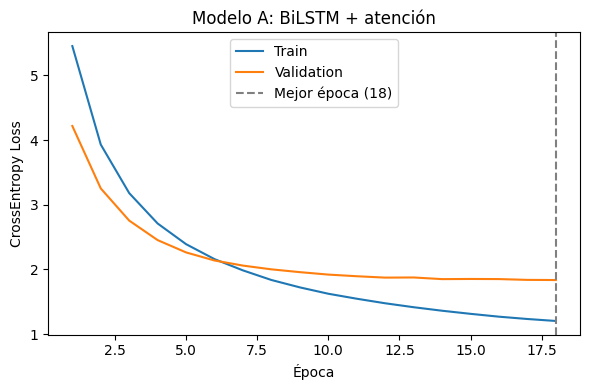

In [13]:
import matplotlib.pyplot as plt, json
tr, va = history['train_loss'], history['val_loss']
best_ep = va.index(min(va)) + 1
print(f'Mejor época: {best_ep} | val_loss {min(va):.4f} | tiempo medio por época: {sum(history["epoch_time"])/len(history["epoch_time"]):.1f}s')

plt.figure(figsize=(6, 4))
plt.plot(range(1, len(tr)+1), tr, label='Train')
plt.plot(range(1, len(va)+1), va, label='Validation')
plt.axvline(best_ep, ls='--', c='gray', label=f'Mejor época ({best_ep})')
plt.xlabel('Época'); plt.ylabel('CrossEntropy Loss'); plt.title('Modelo A: BiLSTM + atención')
plt.legend(); plt.tight_layout()
os.makedirs('figures', exist_ok=True); os.makedirs('results', exist_ok=True)
plt.savefig('figures/curvas_modeloA.png', dpi=200)
json.dump(history, open('results/modeloA_history.json', 'w'))
plt.show()

In [12]:
en_train = {p[0] for p in train_pairs}
unseen = [i for i, p in enumerate(sample) if p[0] not in en_train]
b_unseen = sacrebleu.corpus_bleu([hyps[i] for i in unseen], [[refs[i] for i in unseen]])
print(f'{len(unseen)}/{len(sample)} sin fuente vista | BLEU solo no vistas:', b_unseen)
print('<unk> en las salidas:', sum(h.split().count('<unk>') for h in hyps))

432/500 sin fuente vista | BLEU solo no vistas: BLEU = 32.44 59.6/39.2/26.1/18.2 (BP = 1.000 ratio = 1.048 hyp_len = 4166 ref_len = 3976)
<unk> en las salidas: 159


In [14]:
hyps_fix = [h.replace('<unk>', 'unk') for h in hyps]
print(sacrebleu.corpus_bleu(hyps_fix, [refs]))

BLEU = 35.94 64.8/43.7/30.0/21.5 (BP = 0.978 ratio = 0.978 hyp_len = 4439 ref_len = 4538)
